In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

cfb = pd.read_csv("cfb_box-scores_2002-2025.csv", low_memory=False)

fcs_teams = ["Abilene Christian","Alabama A&M","Alabama State","Albany","Alcorn State","Arkansas-Pine Bluff","Austin Peay","Bethune Cookman",
    "Bryant","Bucknell","Cal Poly SLO","Campbell","Central Arkansas","Central Conn. State","Charleston Southern","Chattanooga","Citadel",
    "Colgate","Delaware State","Drake","Duquesne","East Tennessee State","East Texas A&M","Eastern Illinois","Eastern Kentucky","Eastern Washington",
    "Elon University","Florida A&M","Fordham","Furman","Gardner Webb","Grambling State","Hampton","Hofstra","Holy Cross","Houston Christian",
    "Howard","Idaho State","Illinois State","Incarnate Word","Indiana State","Jackson State","LIU","Lafayette","Lamar","Lehigh","Lindenwood","Maine",
    "McNeese State","Mercer","Merrimack","Monmouth","Montana","Montana State","Morgan State","Murray State","New Hampshire","Nicholls State",
    "Norfolk State","North Alabama","North Carolina A&T","North Carolina Central","North Dakota","North Dakota State","Northeastern","Northern Arizona",
    "Northern Colorado","Northern Iowa","Northwestern State","Portland State","Prairie View A&M","Presbyterian","Rhode Island","Richmond",
    "Robert Morris","SE Missouri State","Sacramento State","Sacred Heart","Samford","San Diego","Savannah State","South Carolina State","South Dakota",
    "South Dakota State","Southeastern Louisiana","Southern","Southern Illinois","Southern Utah","St. Francis (PA)","Stephen F. Austin","Stony Brook",
    "Tarleton State","Tennessee State","Tennessee Tech","Tennessee-Martin","Texas Southern","Towson","UC-Davis","Utah Tech","Valparaiso","Villanova",
    "Virginia Military","Wagner","Weber State","Western Carolina","Western Illinois","William & Mary","Wofford","Yale","Youngstown State"
]

cfb=cfb[
    ~cfb["home"].isin(fcs_teams) &
    ~cfb["away"].isin(fcs_teams)
]

fbs_start_year = {
    "Appalachian State": 2014,"Charlotte": 2015,"Coastal Carolina": 2017,"Georgia Southern": 2014,"Georgia State": 2014,"James Madison": 2022,
    "Jacksonville State": 2023,"Kennesaw State": 2024,"Liberty": 2018,"Massachusetts": 2013,"Missouri State": 2025,"Old Dominion": 2014,
    "Sam Houston State": 2023,"South Alabama": 2012,"Texas State": 2012,"UTSA": 2012,"Delaware":2025,"Missouri State":2025
}

def was_fcs(team, season):
    # Permanently FCS
    if team in fcs_teams:
        return True

    # Former FCS team that hadn't moved to FBS yet
    if team in fbs_start_year:
        return season < fbs_start_year[team]

    # Otherwise, treat it as FBS
    return False

cfb = cfb[
    ~cfb.apply(
        lambda row: (
            was_fcs(row["home"], row["season"]) or
            was_fcs(row["away"], row["season"])
        ),
        axis=1
    )
]

In [ ]:
cfb["total_points"] = cfb["score_home"] + cfb["score_away"]
top_games= cfb.sort_values("total_points", ascending=False)
print(top_games[["season","home","away","score_home","score_away","total_points"]].head(20))

       season               home              away  score_home  score_away  \
13778    2018          Texas A&M               LSU          74          72   
16817    2022                SMU           Houston          77          63   
12443    2017            Buffalo  Western Michigan          68          71   
11991    2016         Pittsburgh          Syracuse          76          61   
4184     2007        Boise State            Nevada          69          67   
4380     2007        North Texas              Navy          62          74   
11872    2016               UNLV           Wyoming          69          66   
1318     2003           Kentucky          Arkansas          63          71   
8070     2012      West Virginia            Baylor          70          63   
10228    2014           Marshall  Western Kentucky          66          67   
1824     2004     San Jose State              Rice          70          63   
12010    2016   Middle Tennessee  Florida Atlantic          77  

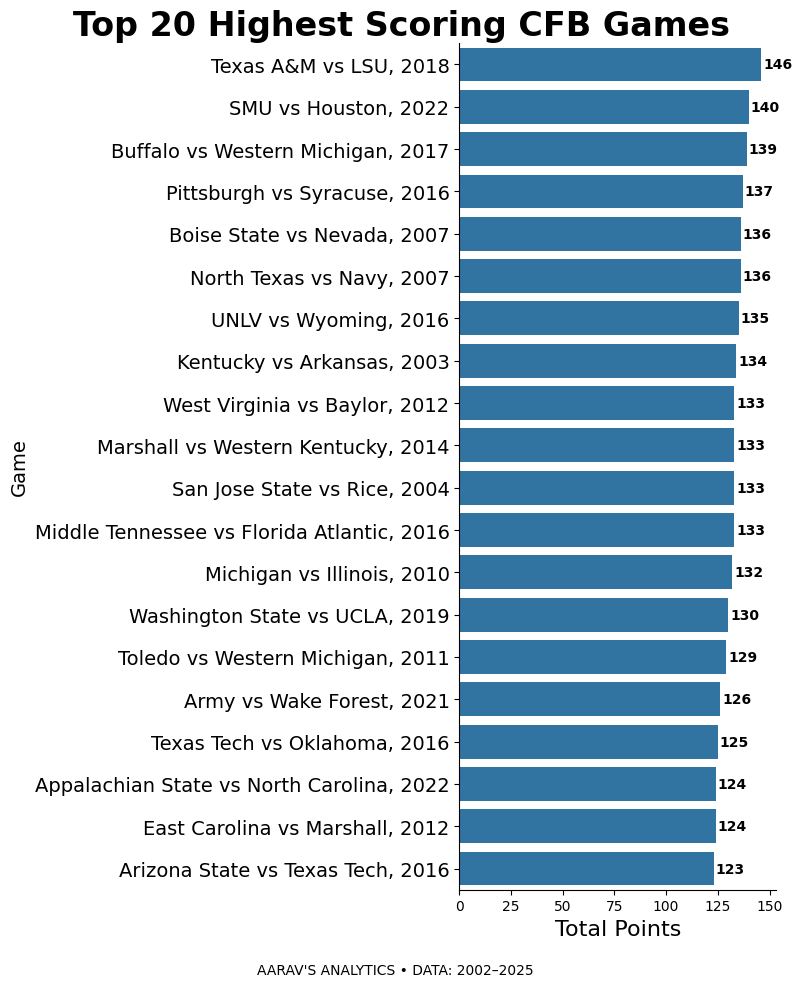

In [ ]:
top_games["matchup"] = (top_games["home"] + " vs " + top_games["away"] + ", " + top_games["season"].astype(str))
top_20 = top_games.head(20).copy()
plt.figure(figsize=(8,10))
ax = sns.barplot(
    data = top_20,
    x="total_points",
    y="matchup"
)

sns.despine()
plt.grid(False)

for i, value in enumerate(top_20["total_points"]):
  ax.text(
      value + 1,
      i,
      str(value),
      va = "center",
      fontweight = "bold"
  )


ax.set_title("Top 20 Highest Scoring CFB Games    ",
             fontsize=24,
             fontweight="bold",
             loc="right")

ax.set_xlabel("Total Points", fontsize=16)
ax.set_ylabel("Game",fontsize=14)
ax.tick_params(axis="y", labelsize=14)

plt.figtext(
    0.5,
    0.02,
    "AARAV'S ANALYTICS • DATA: 2002–2025",
    ha = "center",
    fontsize=10
)

plt.tight_layout(rect=[0,0.04,1,1])
plt.show()

In [ ]:
cfb["margin"] = abs(cfb["score_home"]-cfb["score_away"])
top_blowouts = cfb.sort_values("margin", ascending = False)
print(top_blowouts[["season","home","away","score_home","score_away","margin"]].head(20))

       season              home               away  score_home  score_away  \
11595    2016           Rutgers           Michigan           0          78   
1338     2003          Oklahoma          Texas A&M          77           0   
11489    2016           Memphis      Bowling Green          77           3   
19078    2025           Alabama          UL-Monroe          73           0   
16460    2022  Western Kentucky                FIU          73           0   
17111    2023          Oklahoma     Arkansas State          73           0   
8845     2013        Louisville                FIU          72           0   
13888    2019        Penn State              Idaho          79           7   
6201     2010            Oregon         New Mexico          72           0   
14095    2019        Ohio State         Miami (OH)          76           5   
13989    2019            Oregon             Nevada          77           6   
18225    2024         Tennessee         Kent State          71  

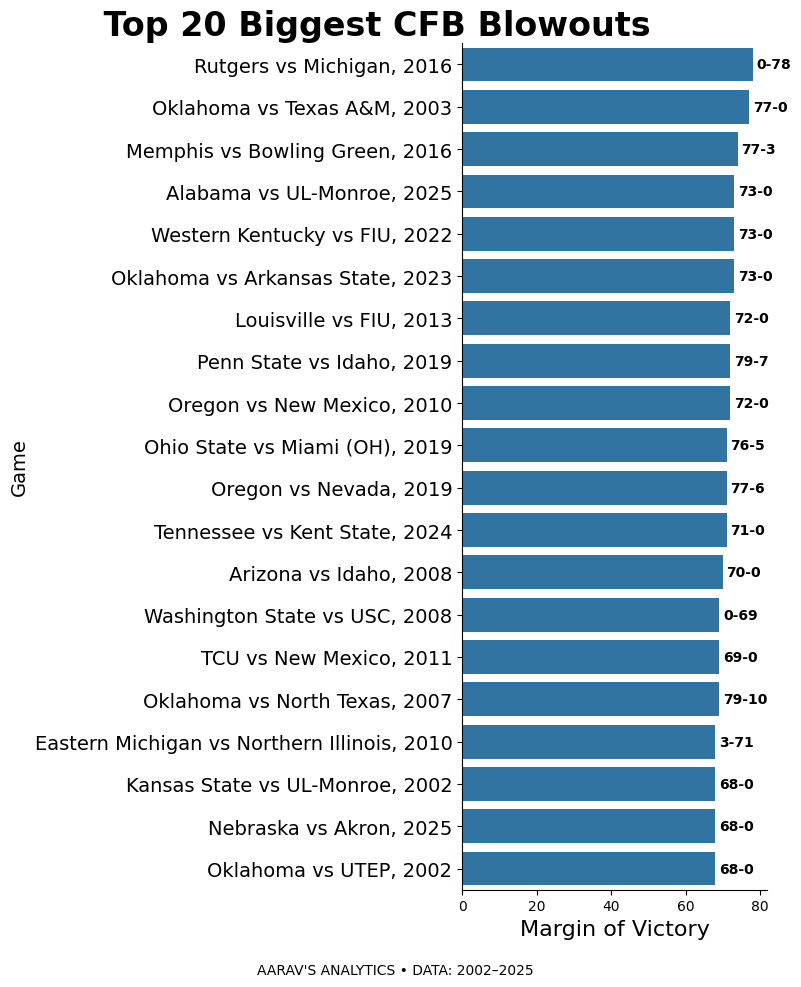

In [ ]:
top_blowouts["matchupb"] = (
    top_blowouts["home"]
    + " vs "
    + top_blowouts["away"]
    + ", "
    + top_blowouts["season"].astype(str))

top_20_blowouts = top_blowouts.head(20).copy()
plt.figure(figsize=(8,10))

ax = sns.barplot(data=top_20_blowouts,
            x="margin",
            y="matchupb")

sns.despine()
plt.grid(False)

for i, value in enumerate(top_20_blowouts["margin"]):
  score = f"{top_20_blowouts.iloc[i]["score_home"]}-{top_20_blowouts.iloc[i]["score_away"]}"
  ax.text(
      value + 1,
      i,
      score,
      va = "center",
      fontweight = "bold"
  )

ax.set_title(" Top 20 Biggest CFB Blowouts          ",
             fontsize=24,
             fontweight="bold",
             loc="right")
ax.set_xlabel("Margin of Victory", fontsize=16)
ax.set_ylabel("Game", fontsize=14)
ax.tick_params(axis="y",labelsize=14)

plt.figtext(
    0.5,
    0.02,
    "AARAV'S ANALYTICS • DATA: 2002–2025",
    ha = "center",
    fontsize=10
)

plt.tight_layout(rect=[0,0.04,1,1])
plt.show()

In [ ]:
from numpy import concat
cfb["total_points"]=cfb["score_home"]+cfb["score_away"]
home_games=cfb[["season","home","score_home"]].copy()
home_games = home_games.rename(columns={
    "home": "team",
    "score_home": "points"
})

away_games=cfb[["season","away","score_away"]].copy()
away_games = away_games.rename(columns={
    "away": "team",
    "score_away": "points"
})

all_games = pd.concat([home_games,away_games])
team_ppg = all_games.groupby(["season","team"])["points"].mean()
team_ppg = team_ppg.reset_index()
team_ppg["points"] = team_ppg["points"].round(2)

top_scoring_seasons = team_ppg.sort_values(
    "points",
    ascending=False
).head(20)
print(top_scoring_seasons)

      season            team  points
1246    2012  Louisiana Tech   51.50
1354    2013   Florida State   51.46
1336    2013          Baylor   51.00
791     2008        Oklahoma   50.69
451     2005           Texas   50.15
2272    2020      Kent State   49.75
286     2004      Louisville   49.75
464     2005             USC   49.08
252     2004     Boise State   48.92
1115    2011         Houston   48.77
1153    2011  Oklahoma State   48.69
1276    2012          Oregon   48.50
2229    2020         Alabama   48.46
2043    2018        Oklahoma   48.36
2145    2019             LSU   47.21
513     2006          Hawaii   47.08
2173    2019      Ohio State   46.86
1589    2015          Baylor   46.58
1461    2014          Baylor   46.42
1543    2014             TCU   46.33


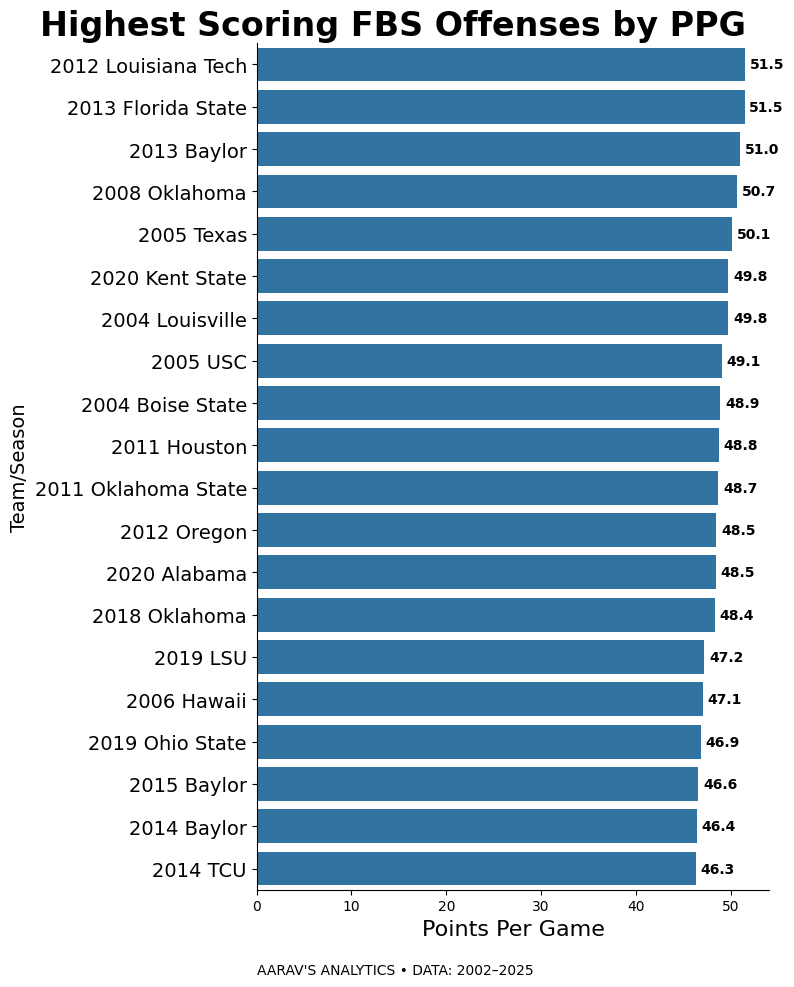

In [ ]:
top_scoring_seasons["team_season"]=(
    top_scoring_seasons["season"].astype(str)
    + " "
    + top_scoring_seasons["team"]
)
plt.figure(figsize=(8,10))
ax = sns.barplot(
    data=top_scoring_seasons,
    x="points",
    y="team_season"
)

sns.despine()
plt.grid(False)

for i, value in enumerate(top_scoring_seasons["points"]):
  ax.text(
      value + 0.5,
      i,
      f"{value:.1f}",
      va = "center",
      fontweight = "bold"
  )

ax.set_title(
     "Highest Scoring FBS Offenses by PPG  ",
     fontsize = 24,
     fontweight = "bold",
     loc = "right"
)

ax.set_xlabel("Points Per Game", fontsize=16)
ax.set_ylabel("Team/Season", fontsize = 14)
ax.tick_params(axis="y",labelsize=14)

plt.figtext(
    0.5,
    0.02,
    "AARAV'S ANALYTICS • DATA: 2002–2025",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()